# Tìm kiếm và suy luận

Nếu biết đầy đủ bản đồ và thời gian đi từng đoạn hành lang, robot ở bài trước không cần học: chỉ cần tìm đường như trong lập trình thi đấu. Bài này học ba loại bài toán tìm kiếm và suy luận trong AI: tìm đường rẻ nhất (A*), chơi trò chơi có đối thủ (minimax), và kiểm một kết luận có chắc chắn đúng từ các điều kiện đã biết (CSP, logic mệnh đề). Đây cũng là AI, dù không học từ dữ liệu.

> **Mục tiêu**
>
> - Chọn BFS, Dijkstra hoặc A*.
> - Tính A* bằng tay; biết khi nào heuristic làm mất lời giải tối ưu.
> - Đọc cây minimax; hiểu alpha-beta và MCTS.
> - Giải một bài CSP nhỏ và kiểm kết luận logic.

## Trạng thái đúng trước, thuật toán sau

Một bài toán tìm kiếm có trạng thái đầu, các hành động hợp lệ, quy tắc sinh trạng thái mới, phép kiểm đích và chi phí.

Nếu hai lịch sử tới cùng vị trí dẫn tới khả năng hành động giống nhau, vị trí có thể làm trạng thái. Nếu robot phải nhặt chìa khóa mới mở được cửa, cần thêm thông tin đã có chìa hay chưa. Đánh dấu `visited[position]` lúc ấy sẽ gộp hai tình huống khác nhau và có thể xóa mất đáp án.

Đồ thị của ta có bốn đỉnh. Từ S có thể tới B với giá 1 hoặc A với giá 2; từ B tới G giá 10, từ A tới G giá 2. Cạnh có hướng, chi phí tính bằng giây, mọi chi phí dương.



BFS mở rộng theo số cạnh nên tối ưu khi mọi cạnh có cùng chi phí. Dijkstra mở rộng theo chi phí đã đi $g(n)$ và cần cạnh không âm. A* thêm một ước lượng chi phí còn lại $h(n)$, mở rộng theo

$$f(n)=g(n)+h(n).$$

Ở đây $g$, $h$, $f$ đều có đơn vị giây. Cộng số bước với số giây không có nghĩa nếu chưa quy đổi. Greedy best-first search chỉ dùng $h$; nó có thể lao tới một đỉnh trông gần đích dù đã đi qua đoạn rất đắt. A* giữ cả chi phí đã trả.

Ta để B đứng trước A trong danh sách cạnh. Hai đường đều có 2 cạnh, nên BFS trả đường qua B; đây là lời giải ít cạnh nhất nhưng không ít giây nhất. Code dưới đây cài BFS trên đúng đồ thị này rồi tính số giây của đường nó trả về.

In [ ]:
from collections import deque
import heapq
import math

graph = {
    "S": [("B", 1), ("A", 2)],
    "A": [("G", 2)],
    "B": [("G", 10)],
    "G": [],
}

def path_cost(path):
    total = 0
    for source, target in zip(path, path[1:]):
        total += next(cost for node, cost in graph[source] if node == target)
    return total

def bfs_path(source, target):
    queue = deque([[source]])
    seen = {source}
    while queue:
        path = queue.popleft()
        if path[-1] == target:
            return path
        for node, _ in graph[path[-1]]:
            if node not in seen:
                seen.add(node)
                queue.append(path + [node])
    return None

bfs_answer = bfs_path("S", "G")
print("BFS:", bfs_answer, "chi phí:", path_cost(bfs_answer))

BFS: ['S', 'B', 'G'] chi phí: 11


Đường dài 11 giây không phải lỗi của BFS; ta đã hỏi nó sai đại lượng. Nếu mọi cạnh là 1 giây thì tối thiểu số cạnh cũng là tối thiểu thời gian.

**Hỏi nhanh.** Robot tới cùng một ô hai lần: một lần đã nhặt chìa khóa, một lần chưa. Có nên gộp hai lần đó thành một trạng thái không?

- A. Nên gộp, vì tọa độ đã mô tả đủ vị trí của robot
- B. Nên gộp, nếu dùng A* thay vì BFS
- C. Không gộp, nếu chìa khóa làm đổi các bước đi được về sau
- D. Không gộp, vì hai lịch sử khác nhau luôn là hai trạng thái

<details><summary>Đáp án</summary>

C. Không gộp, nếu chìa khóa làm đổi các bước đi được về sau

Trạng thái phải giữ đủ thông tin để quyết định các bước hợp lệ về sau: có chìa thì qua được cửa, chưa có thì không. Đổi thuật toán không chữa được một mô hình trạng thái thiếu thông tin. Ngược lại, tách mọi lịch sử thành trạng thái riêng làm số trạng thái bùng nổ. Hai lần tới cùng ô với cùng tình trạng chìa khóa thì vẫn gộp được.

</details>

**Hỏi nhanh.** Đồ thị có cạnh 1 giây và cạnh 2 giây. Một bạn muốn giữ BFS. Sửa thế nào để BFS cho ra đúng đường ít giây nhất?

- A. Giữ BFS, chỉ cộng đúng chi phí từng cạnh khi in đường
- B. Tách mỗi cạnh 2 giây thành hai cạnh 1 giây qua một đỉnh phụ
- C. Đưa các cạnh 1 giây lên trước trong danh sách kề
- D. Đánh dấu đã thăm lúc lấy ra khỏi hàng đợi, không phải lúc đẩy vào

<details><summary>Đáp án</summary>

B. Tách mỗi cạnh 2 giây thành hai cạnh 1 giây qua một đỉnh phụ

Sau khi tách, mọi cạnh có cùng giá, nên số cạnh bằng số giây, và BFS cho đường tối ưu. Cộng đúng chi phí khi in không đổi được đường mà BFS đã chọn. Thứ tự danh sách kề chỉ đổi cách phá hòa giữa các đường có cùng số cạnh. Ở ví dụ, cạnh 1 giây từ S tới B đã đứng trước mà BFS vẫn trả về đường 11 giây. Đổi thời điểm đánh dấu thì vẫn mở theo số cạnh. Khi chi phí cạnh có nhiều giá trị khác nhau, dùng Dijkstra gọn hơn tách cạnh.

</details>

## A*: cần một lời hứa về heuristic

A* ưu tiên mở đỉnh có $f(n)=g(n)+h(n)$ nhỏ nhất, với $g(n)$ là chi phí đã đi và $h(n)$ là ước lượng chi phí còn lại (heuristic). Heuristic gọi là admissible (chấp nhận được) khi không ước lượng quá chi phí thật nhỏ nhất còn lại: $0\leq h(n)\leq h^*(n)$, với $h(G)=0$.

Trên đồ thị này, ta chọn $h(S)=4$, $h(A)=2$, $h(B)=10$, $h(G)=0$. Đó chính là chi phí còn lại thật nên chắc chắn admissible. Ở bài lớn, biết ngay $h^*$ thường khó ngang bài gốc; heuristic hữu ích phải tính rẻ hơn.

Ví dụ quen thuộc là khoảng cách Manhattan trên lưới chỉ đi bốn hướng, mỗi bước tốn ít nhất một đơn vị, không có dịch chuyển tức thời. Bỏ tường làm bài dễ hơn; đường ngắn nhất khi bỏ tường không thể đắt hơn đường có tường. Vì vậy khoảng cách ấy là một cận dưới (lower bound).

Nếu đề có cạnh dịch chuyển hoặc bước đường chéo giá rẻ, chứng minh này phải xem lại.

**Hỏi nhanh.** Robot đi được 8 hướng như quân vua, mỗi bước, kể cả bước chéo, tốn 1 giây, và không có tường. Heuristic nào vừa admissible vừa sát nhất?

- A. $|\Delta x| + |\Delta y|$, tức Manhattan
- B. $\sqrt{\Delta x^2 + \Delta y^2}$, tức Euclid
- C. $\max(|\Delta x|, |\Delta y|)$
- D. $\min(|\Delta x|, |\Delta y|)$

<details><summary>Đáp án</summary>

C. $\max(|\Delta x|, |\Delta y|)$

Tới ô lệch $(3, 3)$ chỉ cần 3 bước chéo. Manhattan cho 6, Euclid cho $3\sqrt2 \approx 4.24$, đều vượt chi phí thật, nên không admissible. Mỗi bước giảm $|\Delta x|$ và $|\Delta y|$ đi nhiều nhất 1, nên cần ít nhất $\max(|\Delta x|, |\Delta y|)$ bước, và không có tường thì đúng bằng số đó. $\min$ cũng là một lower bound, nhưng yếu hơn, nên A* phải mở thêm đỉnh.

</details>



Một điều kiện mạnh hơn là consistency:

$$h(u)\leq c(u,v)+h(v)\quad\text{với mọi cạnh }u\to v.$$

Heuristic consistent (nhất quán) làm $f$ không giảm dọc đường; khi đó A* có thể đóng một trạng thái ngay sau lần đầu lấy nó ra khỏi heap. Nếu chỉ có admissibility, ta phải cho phép mở lại trạng thái khi tìm được $g$ nhỏ hơn. Code dưới đây không dùng một tập `closed` khóa vĩnh viễn, nên vẫn xử lý cập nhật đó.

Tính tay tại S: $g(S)=0$, $f(S)=4$. Sau khi mở S, A có $g=2$, $f=4$; B có $g=1$, $f=11$. A được lấy ra trước, sinh G với $g=4$, $f=4$. G tiếp theo được lấy ra, cho đường 4 giây. Chỉ dừng khi **lấy đích ra khỏi heap**, không dừng ngay khi một cạnh đầu tiên sinh được đích.

In [ ]:
def astar(source, target, heuristic):
    best_cost = {source: 0}
    parent = {source: None}
    heap = [(heuristic[source], 0, source)]
    expanded = []
    while heap:
        _, cost, node = heapq.heappop(heap)
        if cost != best_cost[node]:       # bỏ mục heap đã lỗi thời
            continue
        expanded.append(node)
        if node == target:
            path = []
            while node is not None:
                path.append(node)
                node = parent[node]
            return cost, path[::-1], expanded
        for next_node, edge_cost in graph[node]:
            assert edge_cost >= 0
            candidate = cost + edge_cost
            if candidate < best_cost.get(next_node, math.inf):
                best_cost[next_node] = candidate
                parent[next_node] = node
                priority = candidate + heuristic[next_node]
                heapq.heappush(heap, (priority, candidate, next_node))
    return math.inf, None, expanded

h_good = {"S": 4, "A": 2, "B": 10, "G": 0}
h_zero = {node: 0 for node in graph}
h_bad = {"S": 0, "A": 100, "B": 0, "G": 0}
for name, heuristic in [("Dijkstra", h_zero), ("A*", h_good), ("A* h sai", h_bad)]:
    cost, path, expanded = astar("S", "G", heuristic)
    print(f"{name}: cost={cost}, path={path}, mở={expanded}")

Dijkstra: cost=4, path=['S', 'A', 'G'], mở=['S', 'B', 'A', 'G']
A*: cost=4, path=['S', 'A', 'G'], mở=['S', 'A', 'G']
A* h sai: cost=11, path=['S', 'B', 'G'], mở=['S', 'B', 'G']




Dijkstra là A* với $h=0$. Heuristic đúng giúp tránh mở B trong ví dụ này. Heuristic sai gán 100 cho A, khiến đường qua A bị trì hoãn; G qua B được lấy ra với chi phí 11 và thuật toán dừng. Không được suy ra A* luôn nhanh hơn Dijkstra: heuristic tốn thời gian, có thể yếu, và nhiều đỉnh có cùng $f$ làm thứ tự phá hòa ảnh hưởng số lần mở.

Vì đồ thị hữu hạn và cạnh dương, một đường ngắn nhất không cần lặp đỉnh. Ta viết oracle vét cạn mọi đường đơn. Nó chậm trên đồ thị lớn nhưng độc lập với heap và heuristic, thích hợp để kiểm ví dụ nhỏ như code trâu trong CP.

In [ ]:
def exhaustive_cost(source, target, seen=None):
    seen = {source} if seen is None else seen
    if source == target:
        return 0
    candidates = []
    for node, cost in graph[source]:
        if node not in seen:
            tail = exhaustive_cost(node, target, seen | {node})
            candidates.append(cost + tail)
    return min(candidates, default=math.inf)

truth = {node: exhaustive_cost(node, "G") for node in graph}
assert all(0 <= h_good[node] <= truth[node] for node in graph)
assert all(h_good[u] <= cost + h_good[v] for u in graph for v, cost in graph[u])
assert astar("S", "G", h_good)[0] == truth["S"] == 4
violations = [node for node in graph if h_bad[node] > truth[node]]
print("Chi phí còn lại thật:", truth)
print("Heuristic sai vượt lower bound tại:", violations)

Chi phí còn lại thật: {'S': 4, 'A': 2, 'B': 10, 'G': 0}
Heuristic sai vượt lower bound tại: ['A']


Nhìn danh sách vi phạm: A là bằng chứng cụ thể mất admissibility. Trên bài lớn, kiểm một ít mẫu không thay thế được chứng minh lower bound cho mọi trạng thái. Trong phạm vi đồ thị nhỏ này, ta đã kiểm đủ các đỉnh và cạnh.

**Hỏi nhanh.** Sửa bản Dijkstra, tức $h = 0$, của bài để dừng ngay khi **sinh ra** G, thay vì khi lấy G ra khỏi heap. Trên đồ thị S, A, B, G, nó trả về chi phí bao nhiêu?

- A. 2
- B. 4
- C. 10
- D. 11

<details><summary>Đáp án</summary>

D. 11

Mở S thì được B với $g = 1$ và A với $g = 2$. B ra trước vì có $g$ nhỏ hơn, sinh ra G với $g = 1 + 10 = 11$, và bản sửa dừng ngay. Đường qua A chỉ tốn 4, nhưng A chưa kịp được mở. 10 là riêng cạnh từ B tới G, quên phần đã đi. 2 là số cạnh. Bản đúng đẩy G vào heap với 11, mở A, cập nhật G thành 4, rồi mới lấy G ra.

</details>

## Khi heuristic là một model và thời gian có hạn

Trong bài thi AI, ước lượng chi phí còn lại có khi đến từ một model: một mạng nhìn ảnh bản đồ rồi dự đoán số bước còn lại, hay một hàm đánh giá học từ các lời giải cũ. Model như vậy sai theo cả hai phía. Chỗ nó ước lượng thấp chỉ làm A* mở thêm đỉnh; chỗ nó ước lượng cao có thể đẩy lùi một đường tốt, như $h(A)=100$ ở trên.

Bảo đảm tối ưu mất, nhưng còn một cận. Nếu $h(n)\leq w\,h^*(n)$ ở mọi đỉnh với một hằng $w\geq1$, A* (bản cho mở lại như trên) trả về đường có chi phí không quá $w\,C^*$, trong đó $C^*$ là chi phí tối ưu. Lý do: chừng nào đích chưa được lấy ra, trên một đường tối ưu luôn có một đỉnh $n$ nằm trong heap với $g(n)$ đã bằng chi phí tối ưu từ nguồn tới $n$, nên

$$f(n)\leq g(n)+w\,h^*(n)\leq w\big(g(n)+h^*(n)\big)=w\,C^*.$$

Đích được lấy ra trước $n$, nên chi phí của nó ($g=f$ vì $h=0$ tại đích) không vượt $f(n)$. **Weighted A*** dùng chủ động điều này: lấy $h$ admissible rồi ưu tiên theo $g+w\,h$ với $w>1$. Thuật toán lao về phía đích và mở ít đỉnh hơn, đổi lại chỉ bảo đảm chi phí không quá $w\,C^*$.

Ta thử trên 20 bản đồ lưới $30\times30$, mỗi ô là tường với xác suất 0.3, đi bốn hướng, mỗi bước giá 1, từ góc trên trái tới góc dưới phải. BFS ngược từ đích cho chi phí còn lại thật $h^*$ của mọi ô. Để có một “model” với sai số biết trước, ta nhân $h^*$ của từng ô với một hệ số ngẫu nhiên trong $[0.7, 1.4]$: dự đoán thấp hơn thật tới 30% và cao hơn tới 40%, nên theo cận trên, đường tìm được dài không quá 1.4 lần tối ưu. Weighted A* dùng Manhattan với $w=2$.

In [ ]:
import random

N = 30
START, GOAL = (0, 0), (N - 1, N - 1)

def neighbors(cell, walls):
    r, c = cell
    for nr, nc in [(r + 1, c), (r - 1, c), (r, c + 1), (r, c - 1)]:
        if 0 <= nr < N and 0 <= nc < N and (nr, nc) not in walls:
            yield (nr, nc)

def cost_to_goal(walls):                 # BFS ngược từ đích: h* của mọi ô
    dist = {GOAL: 0}
    queue = deque([GOAL])
    while queue:
        cell = queue.popleft()
        for nxt in neighbors(cell, walls):
            if nxt not in dist:
                dist[nxt] = dist[cell] + 1
                queue.append(nxt)
    return dist

def random_map(seed):
    rng = random.Random(seed)
    while True:                          # bốc lại tới khi START tới được GOAL
        walls = {(r, c) for r in range(N) for c in range(N) if rng.random() < 0.3}
        walls -= {START, GOAL}
        dist = cost_to_goal(walls)
        if START in dist:
            return walls, dist

def grid_astar(walls, h, weight=1):
    best = {START: 0}
    heap = [(weight * h(START), 0, START)]
    expanded = 0
    while heap:
        _, cost, cell = heapq.heappop(heap)
        if cost != best[cell]:
            continue
        expanded += 1
        if cell == GOAL:
            return cost, expanded
        for nxt in neighbors(cell, walls):
            if cost + 1 < best.get(nxt, math.inf):
                best[nxt] = cost + 1
                heapq.heappush(heap, (cost + 1 + weight * h(nxt), cost + 1, nxt))
    return math.inf, expanded

def manhattan(cell):
    return abs(cell[0] - GOAL[0]) + abs(cell[1] - GOAL[1])

results = {"Dijkstra": [], "A* Manhattan": [], "A* model": [], "Weighted A* w=2": []}
for seed in range(20):
    walls, dist = random_map(seed)
    rng = random.Random(1000 + seed)
    factor = {cell: rng.uniform(0.7, 1.4) for cell in dist}   # sai số -30% đến +40%
    def model(cell):
        return dist[cell] * factor[cell]
    setups = [("Dijkstra", lambda cell: 0, 1), ("A* Manhattan", manhattan, 1),
              ("A* model", model, 1), ("Weighted A* w=2", manhattan, 2)]
    for name, h, weight in setups:
        cost, expanded = grid_astar(walls, h, weight)
        results[name].append((cost / dist[START], expanded))

for name, rows in results.items():
    ratios = [ratio for ratio, _ in rows]
    longer = sum(ratio > 1 for ratio in ratios)
    mean_expanded = sum(expanded for _, expanded in rows) / len(rows)
    print(f"{name:15s}  dài hơn tối ưu {longer:2d}/20  tệ nhất x{max(ratios):.3f}  "
          f"mở trung bình {mean_expanded:.1f}")
assert max(r for r, _ in results["A* Manhattan"]) == 1
assert max(r for r, _ in results["A* model"]) <= 1.4
assert max(r for r, _ in results["Weighted A* w=2"]) <= 2

Dijkstra         dài hơn tối ưu  0/20  tệ nhất x1.000  mở trung bình 594.8
A* Manhattan     dài hơn tối ưu  0/20  tệ nhất x1.000  mở trung bình 276.9
A* model         dài hơn tối ưu  9/20  tệ nhất x1.103  mở trung bình 142.4
Weighted A* w=2  dài hơn tối ưu 14/20  tệ nhất x1.310  mở trung bình 115.0


Đọc từng dòng:

- **Manhattan** đúng cả 20 bản đồ và mở trung bình 276.9 ô, chưa tới một nửa 594.8 ô của Dijkstra.
- **Model** mở 142.4 ô, khoảng một nửa Manhattan, nhưng 9 trong 20 bản đồ cho đường dài hơn tối ưu, tệ nhất 1.103 lần.
- **Weighted A*** mở ít nhất, 115.0 ô, với 14 trong 20 bản đồ dài hơn, tệ nhất 1.310 lần.

Hai dòng sau đều nằm dưới cận của mình (1.4 và 2); trên các bản đồ này, đường thực tế còn tốt hơn cận khá nhiều. Muốn đáp án tối ưu chính xác thì chỉ dòng Manhattan dùng được; muốn đổi một chút chất lượng lấy tốc độ thì hai dòng sau cho biết giá phải trả. Số bản đồ bị dài hơn tối ưu còn dao động theo bản đồ được bốc; điều đáng nhớ là thứ tự: heuristic chứng minh được thì tối ưu, model và $w=2$ mở ít đỉnh hơn nhưng có lúc sai.



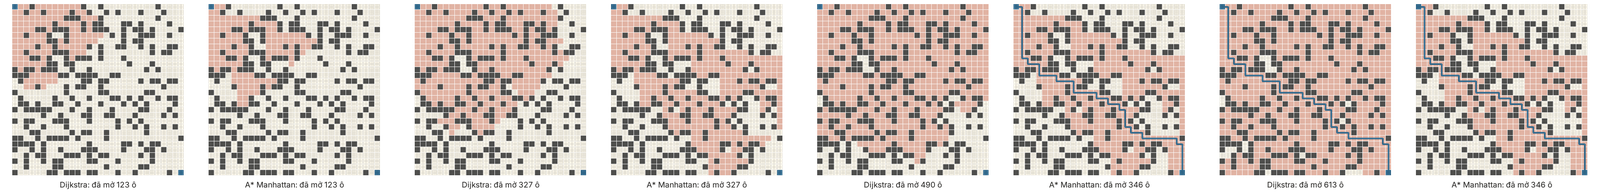

**Hỏi nhanh.** Weighted A* dùng Manhattan với $w = 1.5$, trả về một đường hợp lệ dài 54 bước, và chưa chạy thuật toán nào khác. Ta biết gì về độ dài tối ưu $C^*$?

- A. $36 \leq C^* \leq 54$
- B. $C^* = 54$
- C. $C^* \leq 36$
- D. $54 \leq C^* \leq 81$

<details><summary>Đáp án</summary>

A. $36 \leq C^* \leq 54$

Cận cho $54 \leq 1.5\,C^*$, nên $C^* \geq 36$. Đường dài 54 là hợp lệ, nên đường tối ưu không dài hơn, tức $C^* \leq 54$. Không có gì bảo đảm 54 đã là tối ưu. $54\cdot 1.5 = 81$ là dùng cận theo chiều ngược.

</details>

**Hỏi nhanh.** Đề yêu cầu in đúng độ dài đường ngắn nhất, sai là 0 điểm, và thời gian đủ cho Dijkstra. Theo bảng 20 bản đồ, nên dùng heuristic nào?

- A. Manhattan, vì nó mở ít đỉnh hơn Dijkstra mà vẫn tối ưu
- B. Model, vì nó mở ít đỉnh hơn Manhattan gần một nửa
- C. Weighted A* với $w = 2$, vì nó mở ít đỉnh nhất trong bảng
- D. Không dùng heuristic, vì heuristic nào cũng có thể sai

<details><summary>Đáp án</summary>

A. Manhattan, vì nó mở ít đỉnh hơn Dijkstra mà vẫn tối ưu

Manhattan là một lower bound đã chứng minh được trên lưới bốn hướng, nên A* tối ưu ở cả 20 bản đồ, và chỉ mở 276.9 ô so với 594.8 của Dijkstra. Model mở ít hơn, nhưng sai ở 9 trên 20 bản đồ, còn $w = 2$ sai ở 14. Với đề chấm đúng tối ưu, mỗi lần sai là mất trọn điểm. Bỏ heuristic thì vẫn đúng nhưng phí công. Admissibility của Manhattan là điều chứng minh được, không phải điều phải tin.

</details>

Khi đề giới hạn thời gian, tìm kiếm nên chạy kiểu **anytime** (lúc nào cũng có đáp án): tìm nhanh một lời giải hợp lệ, chẳng hạn bằng weighted A* với $w$ lớn, lưu lại, rồi chạy tiếp với $w$ nhỏ dần tới 1 nếu còn giờ; hết giờ thì nộp lời giải tốt nhất đang có.

Beam search ở bài 6.4 là một cách giới hạn ngân sách khác: mỗi độ sâu chỉ giữ $k$ trạng thái tốt nhất, bộ nhớ cố định, nhưng có thể loại mất lời giải tối ưu, thậm chí mọi lời giải. Trước khi chọn, đo số trạng thái mở được mỗi giây trên test lớn nhất.

## Khi người khác chọn bước tiếp theo: minimax

Tìm đường giả sử environment làm theo quy tắc; chơi cờ còn có đối thủ chọn hành động để giảm điểm của ta. Với trò chơi hai người, tất định, thông tin đầy đủ, tổng lợi ích bằng 0, minimax đánh giá theo giả thiết đối thủ cũng chơi tối ưu.

Xét cây sâu hai lượt. Ta chọn nhánh A hoặc B; sau đó đối thủ chọn một lá. Nhánh A có điểm 3 và 5, nhánh B có điểm 2 và 9; mọi điểm đo từ góc nhìn của ta. Đối thủ ở A chọn 3, ở B chọn 2. Ta nên chọn A vì $\max(\min(3,5),\min(2,9))=3$.



Nếu $U(s)$ là điểm ở lá terminal, định nghĩa đệ quy là $V(s)=\max V(s')$ ở lượt MAX và $V(s)=\min V(s')$ ở lượt MIN. Đừng chọn lá lớn nhất của toàn cây: đường tới lá đó có thể đòi đối thủ hợp tác.

In [ ]:
def minimax(tree, maximizing=True):
    if isinstance(tree, (int, float)):
        return tree
    child_values = [minimax(child, not maximizing) for child in tree]
    return max(child_values) if maximizing else min(child_values)

game_tree = [[3, 5], [2, 9]]
branch_values = [minimax(branch, maximizing=False) for branch in game_tree]
print("Giá trị hai nhánh:", branch_values)
print("Minimax:", minimax(game_tree), "chọn A:", branch_values[0] > branch_values[1])
assert minimax(game_tree) == 3

Giá trị hai nhánh: [3, 2]
Minimax: 3 chọn A: True


**Hỏi nhanh.** Gốc là MAX, có hai nhánh MIN. Nhánh A có lá 4 và 6, nhánh B có lá 2 và 9. Vì sao MAX không chọn B để nhắm tới 9?

- A. MAX nên chọn B, vì 9 là lá lớn nhất cây
- B. MAX nên chọn B, vì trung bình lá của B là 5.5, hơn 5
- C. Vì ở B đối thủ sẽ chọn 2, còn A bảo đảm ít nhất 4
- D. Vì ở A đối thủ sẽ chọn 6, còn B chỉ bảo đảm 2

<details><summary>Đáp án</summary>

C. Vì ở B đối thủ sẽ chọn 2, còn A bảo đảm ít nhất 4

Minimax tính $\min(4, 6) = 4$ và $\min(2, 9) = 2$, rồi MAX lấy 4. Nhắm tới lá 9 là giả định đối thủ hợp tác với mình. Lấy trung bình là mô hình một đối thủ chọn ngẫu nhiên, không phải đối thủ tối ưu. MIN ở A chọn 4 chứ không chọn 6, vì đối thủ muốn giảm điểm của MAX.

</details>

Alpha-beta pruning bỏ những nhánh đã chắc chắn không thay đổi quyết định minimax. Trong cây trên, xét A trước thì MAX đã bảo đảm được 3. Sang B, lá đầu là 2 nên MIN ở B sẽ trả không quá 2, kém hơn 3; lá 9 không cần đọc. Giá trị minimax giữ nguyên, còn thứ tự xét nước đi quyết định cắt được bao nhiêu: xét nước tốt trước thì cắt nhiều hơn.

Với cây đầy đủ hệ số nhánh $b$ và độ sâu $d$, minimax có thể phải xét $O(b^d)$ lá. Vì vậy game lớn thường dùng giới hạn độ sâu và evaluation function. Khi cắt trước terminal, giá trị lá chỉ là ước lượng, nên không còn bảo đảm kết quả của cây trò chơi đầy đủ.

**Hỏi nhanh.** Gốc là MAX, có ba nhánh MIN, xét từ trái sang phải. A có lá 6 và 4, B có lá 3 và 8, C có lá 5 và 1. Alpha-beta không cần đọc lá nào?

- A. Chỉ lá 8
- B. Lá 8 và lá 1
- C. Lá 4 và lá 8
- D. Không lá nào, vì nhánh nào cũng phải xét

<details><summary>Đáp án</summary>

A. Chỉ lá 8

A cho 4, nên MAX có ít nhất 4. Ở B, lá 3 đã không quá 4, nên bỏ qua lá 8. Ở C, lá 5 còn lớn hơn 4, và MIN có thể xuống thấp hơn, nên phải đọc lá 1. Sau đó C cho 1. Lá 4 phải đọc, vì lúc xét A chưa có mốc nào. Giá trị ở gốc là 4, đúng như minimax đầy đủ.

</details>



Nếu có xúc xắc, tầng chance lấy kỳ vọng theo xác suất chứ không lấy min. Nếu đối thủ không phải người chơi đối kháng tối ưu, giả thiết minimax cũng cần cân nhắc. Ta phải xác định mô hình tương tác trước khi chọn phép gộp giá trị.

Evaluation function ở độ sâu cắt có thể là một model học từ ván đấu. Với game có hệ số nhánh rất lớn như cờ vây, **Monte Carlo tree search (MCTS)** không mở đều mọi nhánh mà dồn ngân sách mô phỏng vào nhánh hứa hẹn. Mỗi lượt mô phỏng đi từ gốc xuống; tại mỗi nút, chọn con $i$ có

$$\bar v_i+c\sqrt{\frac{\ln N}{n_i}}$$

lớn nhất, với $\bar v_i$ là điểm trung bình của con $i$ theo góc nhìn người chọn nước ở nút cha, $n_i$ là số lần thăm con đó, $N$ là số lần thăm nút cha; con chưa thăm được thử trước.

Tới nút chưa mở thì mở rộng, đánh giá bằng một ván chơi ngẫu nhiên tới cuối hoặc bằng một model, rồi cộng kết quả ngược lên mọi nút trên đường đã đi. Số hạng thứ nhất khai thác nhánh đang tốt, số hạng thứ hai ưu tiên nhánh còn ít được thử. Hết ngân sách thì chọn nước ở gốc được thăm nhiều nhất.

AlphaZero thay ván chơi ngẫu nhiên bằng value network và dùng policy network để ưu tiên nước đi.

## Ràng buộc: không phải mọi bài đều hỏi đường đi

Nhà trường cần xếp ba nhóm A, B, C vào hai phòng 0 và 1. A và B phải khác phòng, B và C phải khác phòng; A được ấn định ở phòng 0. Ta không quan tâm thứ tự thao tác xếp, chỉ quan tâm bộ gán cuối có hợp lệ không.

Đây là bài toán thỏa mãn ràng buộc (constraint satisfaction problem, CSP): biến là phòng của mỗi nhóm, domain là $\{0,1\}$, constraints là $A\ne B$, $B\ne C$, $A=0$. Tính tay: $A=0$ buộc $B=1$; từ đó $C=0$. A và C dùng chung phòng được vì đề không cấm. Tự thêm $A\ne C$ sẽ làm một đề có nghiệm thành vô nghiệm.



Quay lui gán từng biến và bỏ ngay nhánh đã vi phạm một điều kiện có đủ biến. Đây là pruning bằng tính hợp lệ; khác heuristic ước lượng chi phí của A*. Ta cài trên đúng ba biến rồi so với vét cạn toàn bộ $2^3=8$ bộ gán.

In [ ]:
from itertools import product

variables = ["A", "B", "C"]
edges = [("A", "B"), ("B", "C")]

def consistent(assignment):
    if "A" in assignment and assignment["A"] != 0:
        return False
    for left, right in edges:
        if left in assignment and right in assignment:
            if assignment[left] == assignment[right]:
                return False
    return True

def backtrack(assignment):
    if len(assignment) == len(variables):
        return [assignment.copy()]
    variable = variables[len(assignment)]
    answers = []
    for room in [0, 1]:
        assignment[variable] = room
        if consistent(assignment):
            answers.extend(backtrack(assignment))
        del assignment[variable]
    return answers

csp_answers = backtrack({})
oracle_answers = []
for rooms in product([0, 1], repeat=3):
    A, B, C = rooms
    if A == 0 and A != B and B != C:
        oracle_answers.append(dict(zip(variables, rooms)))
assert csp_answers == oracle_answers
print("Nghiệm CSP:", csp_answers)
print("Khớp vét cạn:", csp_answers == oracle_answers)

Nghiệm CSP: [{'A': 0, 'B': 1, 'C': 0}]
Khớp vét cạn: True


Với nhiều biến, minimum remaining values (MRV) chọn biến còn ít giá trị hợp lệ nhất để sớm gặp nhánh thất bại. Forward checking loại khỏi domain các giá trị đã xung đột với biến mới gán. Những kỹ thuật này giảm công tìm, nhưng domain và constraints vẫn phải mô tả đúng bài; chúng không tạo thêm một điều kiện mà đề không có.

**Hỏi nhanh.** Thêm nhóm D phải khác phòng với cả A và B, vẫn chỉ có hai phòng, và $A = 0$. Quay lui gán theo thứ tự A, B, C, D, có forward checking. Vô nghiệm được phát hiện sớm nhất vào lúc nào?

- A. Chỉ khi gán tới D và đã thử cả hai phòng
- B. Sau khi gán C, vì C và D cùng nối với B
- C. Ngay sau khi gán B, vì domain của D đã rỗng
- D. Không phát hiện được, vì $D = 0$ hợp lệ khi C cũng ở phòng 0

<details><summary>Đáp án</summary>

C. Ngay sau khi gán B, vì domain của D đã rỗng

Gán $A = 0$ loại 0 khỏi domain của B và của D. Gán $B = 1$ loại 1 khỏi domain của C và của D. D hết giá trị, nên nhánh này bị bỏ ngay, chưa cần gán C. Quay lui thuần thì phải tới D mới thấy. $D = 0$ vi phạm $D \ne A$, và đề không có ràng buộc nào giữa C và D. A và B đã chiếm cả hai phòng, nên bài vô nghiệm dù xếp C thế nào.

</details>



## Từ một nghiệm tới một kết luận logic

Tìm được một bộ gán hợp lệ trả lời câu hỏi “có thể xếp thế nào?”. Muốn kết luận “C bắt buộc ở phòng 0”, cần kiểm **mọi** bộ gán hợp lệ.

Đặt $P$: A ở phòng 0; $Q$: B ở phòng 0; $R$: C ở phòng 0. Vì mỗi nhóm có đúng hai lựa chọn, điều kiện khác phòng tương đương XOR: một mệnh đề đúng, mệnh đề còn lại sai. Knowledge base (KB) là

$$P\land(P\oplus Q)\land(Q\oplus R).$$

$\land$ nghĩa là “và”, $\neg$ là “không”, $\oplus$ là XOR. Ta cũng dùng $\lor$ (“hoặc”) và $P\Rightarrow Q$ (“nếu P thì Q”); mệnh đề kéo theo chỉ sai khi P đúng mà Q sai, nên tương đương $\neg P\lor Q$. Ta viết $KB\models R$ (KB suy ra R) nếu mọi phép gán làm KB đúng cũng làm $R$ đúng; mỗi phép gán như vậy gọi là một model của KB. “Đúng trong một nghiệm” yếu hơn “đúng trong mọi nghiệm”.

Khi bỏ điều kiện $P$, vẫn có cách xếp hợp lệ với C ở phòng 1, nên kết luận trước không còn được suy ra.

In [ ]:
worlds = list(product([False, True], repeat=3))
models = [(P, Q, R) for P, Q, R in worlds if P and (P != Q) and (Q != R)]
models_without_P = [(P, Q, R) for P, Q, R in worlds if (P != Q) and (Q != R)]
assert models                  # kiểm KB có nghiệm trước khi diễn giải
entails_R = all(R for P, Q, R in models)
counterexamples = [world for world in models_without_P if not world[2]]
print("Models của KB:", models)
print("KB suy ra R:", entails_R)
print("Bỏ P, phản ví dụ cho R:", counterexamples)
assert entails_R and counterexamples

Models của KB: [(True, False, True)]
KB suy ra R: True
Bỏ P, phản ví dụ cho R: [(False, True, False)]


`all` trên danh sách rỗng của Python trả `True`. Trong logic cổ điển, KB mâu thuẫn cũng suy ra mọi mệnh đề theo định nghĩa entailment, vì không còn model phản ví dụ. Với hệ thống xếp phòng, điều ta cần báo trước là **không có cách xếp hợp lệ**, không diễn giải đó thành bằng chứng C ở phòng 0. Vì vậy kiểm satisfiability trước khi đọc kết luận.



**Hỏi nhanh.** Quay lui tìm được một cách xếp hợp lệ có C ở phòng 0. Đã chứng minh được C luôn ở phòng 0 chưa?

- A. Rồi, vì cách xếp đó thỏa mọi ràng buộc
- B. Rồi, vì quay lui duyệt theo một thứ tự cố định
- C. Chưa, phải tìm thêm một cách xếp nữa có C ở phòng 0
- D. Chưa, phải chắc rằng không model nào có C ở phòng 1

<details><summary>Đáp án</summary>

D. Chưa, phải chắc rằng không model nào có C ở phòng 1

Entailment xét mọi model của KB. Một cách xếp hợp lệ, tức một witness, chỉ cho thấy KB thỏa được, và C ở phòng 0 là có thể xảy ra. Thêm vài nghiệm cùng tính chất vẫn chưa đủ. Phải loại hết khả năng C ở phòng 1, chẳng hạn bằng vét cạn, hoặc chứng minh $KB\land\neg R$ vô nghiệm.

</details>

**Hỏi nhanh.** Luật nói: nếu trời mưa thì sân ướt, tức $M \Rightarrow U$. Quan sát thấy sân ướt. Với $KB = (M \Rightarrow U)\land U$, có $KB \models M$ không?

- A. Có, vì luật nối thẳng M với U
- B. Không, vì model có $M$ sai và $U$ đúng vẫn thỏa KB
- C. Có, vì KB chỉ có đúng một model
- D. Không, vì KB mâu thuẫn nên không suy ra được gì

<details><summary>Đáp án</summary>

B. Không, vì model có $M$ sai và $U$ đúng vẫn thỏa KB

KB có hai model, với $(M, U)$ là (đúng, đúng) và (sai, đúng). Model thứ hai là phản ví dụ cho M, vì sân có thể ướt do lý do khác. Đây là lỗi “khẳng định hệ quả”. KB thỏa được nên không mâu thuẫn. Nếu nó mâu thuẫn thì theo định nghĩa, nó lại suy ra được mọi mệnh đề.

</details>

## Khi đi thi

- **Viết trạng thái trước khi viết code.** Vẽ một instance nhỏ, ghi rõ trạng thái gồm những gì (vị trí, hướng, chìa khóa…), mục tiêu và đơn vị chi phí. Đề cho luật tất định dưới dạng phần thưởng thì đổi thành chi phí rồi search, không cần học.
- **Đọc đề chấm đúng tối ưu hay chấm theo chất lượng.** Chấm đúng tối ưu: BFS, Dijkstra hoặc A* với lower bound chứng minh được. Chấm theo tỉ lệ so với tối ưu: weighted A*, beam search hoặc heuristic từ model, miễn biết mình đang đổi chất lượng lấy tốc độ đến đâu.
- **Luôn có một đáp án hợp lệ để nộp.** Đo số trạng thái mở mỗi giây trên test lớn nhất; nếu không chắc kịp giờ, tìm nhanh một lời giải rồi cải thiện trong thời gian còn lại.
- **Model chỉ xếp thứ tự, luật của đề quyết định hợp lệ.** Điểm model dùng để chọn nhánh nào xét trước; nước đi, đường đi, bộ gán vẫn kiểm bằng quy tắc của đề.
- **Đối chiếu bằng vét cạn trên ví dụ nhỏ.** Với A*, CSP và logic, oracle vét cạn vài biến bắt được heuristic vượt, ràng buộc tự thêm hay KB vô nghiệm trước khi chạy test lớn.

## Tóm tắt

- Tìm kiếm cần trạng thái đủ thông tin và đúng đại lượng chi phí. BFS, Dijkstra, A* khác nhau ở thứ tự mở rộng.
- A* dùng $g+h$; lower bound và cách xử lý đường tốt hơn giữ bảo đảm tối ưu. Heuristic quá lớn có thể cho đáp án sai.
- Heuristic từ model hay weighted A* đổi bảo đảm tối ưu lấy tốc độ: nếu $h\leq w\,h^*$ thì chi phí không quá $w\,C^*$. Khi thời gian có hạn, giữ sẵn một lời giải hợp lệ rồi cải thiện dần.
- Minimax xét phản ứng của đối thủ; giá trị của một nhánh không phải lá lớn nhất trong nhánh đó. Alpha-beta bỏ nhánh mà giữ giá trị; MCTS dồn ngân sách mô phỏng vào nhánh hứa hẹn.
- CSP tìm phép gán thỏa mọi ràng buộc. Suy diễn ($KB\models R$) kiểm kết luận trên mọi model của KB; cần nhận ra KB vô nghiệm trước khi diễn giải.

## Kiểm tra cuối bài

**Câu 1.** Robot quay được bốn hướng, và mỗi hành động là quay trái, quay phải, hay tiến một ô, đều tốn 1. Robot đang đứng quay lên phía bắc, còn đích nằm thẳng về phía đông, cách 6 ô, trên một hàng không có tường. Heuristic $h$ là số ô còn lại tới đích, tức 6, bỏ qua việc quay. Chọn nhận định đúng về $h$, và về chi phí tối ưu của kế hoạch **bắt đầu bằng quay trái**.

- A. $h$ admissible, và kế hoạch đó tốn 7
- B. $h$ không admissible, và kế hoạch đó tốn 9
- C. $h$ admissible, và kế hoạch đó tốn 9
- D. $h$ không admissible, và kế hoạch đó tốn 8

<details><summary>Đáp án</summary>

C. $h$ admissible, và kế hoạch đó tốn 9

Chi phí thật từ trạng thái đầu là 7, gồm một lần quay phải rồi 6 lần tiến. Vì $h = 6 \leq 7$ nên $h$ admissible, dù không sát vì bỏ qua lần quay. Quay trái trước thì robot quay về phía tây, phải quay thêm hai lần mới hướng về đông, nên tốn $1 + 2 + 6 = 9$. Hướng nằm trong trạng thái, nên hai lần ở cùng một ô nhưng khác hướng là hai đỉnh khác nhau, và một lần quay sai làm mất đúng hai hành động. 7 là chi phí của kế hoạch tốt nhất, bắt đầu bằng quay phải. 8 là quên một trong hai lần quay bù.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q3.4](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=15)

</details>

**Câu 2.** Đồ thị có cạnh âm: $S \to A$ giá 2, $S \to B$ giá 3, $B \to A$ giá $-2$, $A \to G$ giá 1. Dijkstra đóng đỉnh ngay khi lấy nó ra khỏi heap sẽ trả về chi phí $S \to G$ bằng bao nhiêu, và chi phí nhỏ nhất thật là bao nhiêu?

- A. Trả về 2, và nhỏ nhất thật là 2
- B. Trả về 3, và nhỏ nhất thật là 3
- C. Trả về 4, và nhỏ nhất thật là 2
- D. Trả về 3, và nhỏ nhất thật là 2

<details><summary>Đáp án</summary>

D. Trả về 3, và nhỏ nhất thật là 2

Lấy S ra thì đẩy A với 2 và B với 3. Lấy A ra với 2 và đóng nó lại, đẩy G với 3. Khi lấy B ra, đường $S \to B \to A$ chỉ tốn $3 - 2 = 1 < 2$, nhưng A đã đóng nên bị bỏ qua, và G ra với 3. Đường thật là $S \to B \to A \to G$, tốn $3 - 2 + 1 = 2$. Dijkstra dựa trên giả thiết thêm cạnh chỉ làm chi phí tăng, nên đỉnh ở đầu heap đã là tối ưu. Cạnh âm phá vỡ giả thiết ấy. Khi có cạnh âm thì cần một thuật toán khác, chẳng hạn Bellman–Ford.

</details>

**Câu 3.** Heuristic $h$ admissible ở mọi đỉnh, nhưng có một cạnh $u \to v$ giá 1 với $h(u) = 6$ và $h(v) = 3$. Một bản A* đóng vĩnh viễn mỗi đỉnh ngay khi lấy nó ra khỏi heap. Nhận định nào đúng?

- A. $h$ không consistent, nên bản đóng vĩnh viễn có thể trả về đường đắt hơn
- B. $h$ không consistent, nhưng admissible là đủ cho bản đóng vĩnh viễn
- C. $h$ vẫn consistent vì $6 \geq 3 + 1$, nên bản đóng vĩnh viễn vẫn đúng
- D. $h$ không admissible, nên mọi bản A* đều có thể trả về đường đắt hơn

<details><summary>Đáp án</summary>

A. $h$ không consistent, nên bản đóng vĩnh viễn có thể trả về đường đắt hơn

Consistency đòi $h(u) \leq c(u, v) + h(v) = 4$, mà ở đây $h(u) = 6$. Khi đó $f$ có thể giảm dọc theo đường đi, và một đỉnh có thể được lấy ra lần đầu với $g$ chưa phải tốt nhất. Khóa nó lại thì đường rẻ hơn tới sau sẽ bị bỏ. Admissible vẫn đủ cho bản cho phép mở lại, như code của bài, nhưng không đủ cho bản đóng vĩnh viễn. $6 \geq 4$ là viết điều kiện theo chiều ngược. Còn admissibility thì đề đã cho sẵn.

</details>

**Câu 4.** Lưới $10\times 10$, đi bốn hướng, mỗi bước giá 1, có thêm một cổng một chiều: đứng ở ô $P = (0, 9)$ có thể dịch tới $Q = (9, 0)$ với giá 1. Đích là $G = (9, 1)$, và $M(a, b)$ là khoảng cách Manhattan. Heuristic nào vẫn là lower bound ở mọi ô $n$?

- A. $M(n, G)$
- B. $M(n, G)/2$
- C. $\max\big(M(n, G),\ M(n, P) + 1 + M(Q, G)\big)$
- D. $\min\big(M(n, G),\ M(n, P) + 1 + M(Q, G)\big)$

<details><summary>Đáp án</summary>

D. $\min\big(M(n, G),\ M(n, P) + 1 + M(Q, G)\big)$

Một đường tới G hoặc không dùng cổng, khi đó dài ít nhất $M(n, G)$. Hoặc có dùng cổng: trước lần dịch đầu phải đi tới P, ít nhất $M(n, P)$, cộng 1 cho lần dịch, và sau lần dịch cuối phải đi từ Q tới G, ít nhất $M(Q, G)$. Lấy min của hai trường hợp thì được một lower bound. Tại $n = (0, 8)$, $M(n, G) = 16$, nhưng đường thật chỉ dài $1 + 1 + 1 = 3$. Vì vậy Manhattan, một nửa của nó là 8, và phép max đều vượt chi phí thật.

</details>

**Câu 5.** Từ trạng thái B có hai hành động. Sang A thì nhận thưởng 50, và giá trị của A hội tụ về 40. Sang C thì nhận thưởng 30, và giá trị của C hội tụ về 100. Với $\gamma = 0.9$, value iteration bắt đầu từ $V = 0$ ở mọi trạng thái. Hành động tốt nhất ở B sau lần cập nhật đầu tiên, và sau khi các giá trị đã hội tụ, lần lượt là gì?

- A. Sang C ngay từ đầu, và sang C khi hội tụ
- B. Sang A lúc đầu, rồi sang C khi hội tụ
- C. Sang A lúc đầu, và vẫn sang A khi hội tụ
- D. Sang C lúc đầu, rồi sang A khi hội tụ

<details><summary>Đáp án</summary>

B. Sang A lúc đầu, rồi sang C khi hội tụ

Lúc đầu mọi $V = 0$, nên chỉ có thưởng tức thời được tính: $50 > 30$, chọn A. Khi hội tụ, sang A cho $50 + 0.9\cdot 40 = 86$, sang C cho $30 + 0.9\cdot 100 = 120$, nên chọn C, và $V(B) = 120$. Chọn theo thưởng tức thời cũng là tham lam như greedy best-first, bỏ qua phần còn lại của đường. Chọn C ngay từ đầu cần giá trị tương lai mà lúc đó chưa tính. Giữ A khi hội tụ là bỏ qua $V(A) = 40 < V(C) = 100$. Đảo thứ tự thì sai cả hai bước.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q4.3](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=19)

</details>

**Câu 6.** Đề game: sau nước đi của ta, bot đối thủ chọn **ngẫu nhiên đều** giữa hai nước, và điểm là trung bình qua 1000 ván. Nhánh A dẫn tới lá 5 hoặc 7, nhánh B dẫn tới lá 2 hoặc 12, đều là điểm của ta. Nên chọn nhánh nào?

- A. A, vì minimax bảo đảm được 5
- B. A, vì kỳ vọng bằng 6
- C. B, vì có lá cao nhất là 12
- D. B, vì kỳ vọng bằng 7

<details><summary>Đáp án</summary>

D. B, vì kỳ vọng bằng 7

Bot chọn ngẫu nhiên, nên nút của nó là một tầng chance. A có kỳ vọng $(5 + 7)/2 = 6$, còn B có $(2 + 12)/2 = 7$. Minimax giả định đối thủ tối ưu, nên chọn A vì bảo đảm được 5. Cách ấy an toàn hơn trong một ván, nhưng cho điểm trung bình thấp hơn ở đề này. Lá 12 không phải lý do: nếu B dẫn tới 2 hoặc 9 thì kỳ vọng chỉ là 5.5, lại kém A.

</details>

**Câu 7.** MCTS ở gốc đã chạy 20 lượt mô phỏng. Nước A được thăm 10 lần, điểm trung bình 0.6. Nước B được thăm 2 lần, trung bình 0.5. Nước C được thăm 8 lần, trung bình 0.3. Con được chọn theo $\bar v_i + \sqrt{\ln N/n_i}$, với $c = 1$. Lượt mô phỏng tiếp theo đi vào nhánh nào, và nếu hết ngân sách ngay lúc này thì nộp nước nào?

- A. Mô phỏng tiếp vào A, và nộp A
- B. Mô phỏng tiếp vào B, nhưng nộp A
- C. Mô phỏng tiếp vào B, và nộp B
- D. Mô phỏng tiếp vào A, nhưng nộp B

<details><summary>Đáp án</summary>

B. Mô phỏng tiếp vào B, nhưng nộp A

$\ln 20 \approx 3.00$. A được $0.6 + \sqrt{0.30} \approx 1.15$, B được $0.5 + \sqrt{1.50} \approx 1.72$, C được $0.3 + \sqrt{0.37} \approx 0.91$. B mới thử 2 lần, nên số hạng khám phá lớn, và B được chọn. Khi nộp thì không cần khám phá nữa. Hãy chọn nước được thăm nhiều nhất là A, cũng là nước có trung bình cao nhất trên nhiều mẫu nhất. Trung bình 0.5 của B chỉ dựa trên 2 lượt, nên còn rất nhiễu.

</details>

**Câu 8.** Xếp bốn nhóm A, B, C, D vào ba phòng, sao cho các cặp kề nhau trên vòng A–B–C–D–A khác phòng: $A \ne B$, $B \ne C$, $C \ne D$, $D \ne A$. Có bao nhiêu cách xếp?

- A. 12
- B. 18
- C. 24
- D. 81

<details><summary>Đáp án</summary>

B. 18

A có 3 cách, B có 2 cách. Nếu $C = A$, có 1 cách, thì D chỉ cần khác A, có 2 cách. Nếu C khác cả A và B, có 1 cách, thì D phải khác C và khác A, là hai phòng khác nhau, nên còn 1 cách. Tổng cộng $3\cdot 2\cdot(2 + 1) = 18$. Vét cạn $3^4 = 81$ bộ gán cũng đếm ra 18. 24 là $3\cdot 2\cdot 2\cdot 2$, quên rằng D còn bị ràng buộc với A. 12 là cho D luôn chỉ còn một phòng, quên trường hợp $C = A$. 81 là bỏ qua mọi ràng buộc.

</details>

**Câu 9.** $KB = (P\lor Q)\land(\neg P\lor R)$. Kết luận nào được suy ra từ KB?

- A. $Q\lor R$, nhưng không phải $Q$
- B. Cả $Q$ lẫn $Q\lor R$
- C. Chỉ $R$, nhờ mệnh đề $\neg P\lor R$
- D. Không suy ra được gì, vì KB có tới 4 model

<details><summary>Đáp án</summary>

A. $Q\lor R$, nhưng không phải $Q$

Nếu P đúng thì mệnh đề thứ hai buộc R đúng. Nếu P sai thì mệnh đề thứ nhất buộc Q đúng. Vậy trong mọi model, $Q\lor R$ đều đúng. Liệt kê $(P, Q, R)$, với 1 là đúng, thì KB có 4 model là $(0, 1, 0)$, $(0, 1, 1)$, $(1, 0, 1)$ và $(1, 1, 1)$. Model $(1, 0, 1)$ có Q sai, và model $(0, 1, 0)$ có R sai, nên Q và R riêng lẻ đều không được suy ra. Có nhiều model không cản entailment, chỉ cần kết luận đúng trong tất cả các model.

</details>

**Câu 10.** Đề tìm đường giới hạn mỗi test 2 giây. Điểm bằng độ dài tối ưu chia cho độ dài đường nộp, và không nộp được đường hợp lệ thì 0 điểm. Thử trên máy, A* với Manhattan xong trong 2 giây ở 70% số test, còn lại thì hết giờ. Chiến lược nào hợp lý nhất?

- A. Chỉ chạy A* với Manhattan, chấp nhận 0 điểm ở 30% số test
- B. Dùng greedy best-first, chỉ dựa vào $h$, cho mọi test vì nhanh nhất
- C. Lấy nhanh một đường bằng $w$ lớn, rồi giảm dần $w$ khi còn thời gian
- D. Dùng beam search độ rộng 1 cho mọi test để tiết kiệm bộ nhớ

<details><summary>Đáp án</summary>

C. Lấy nhanh một đường bằng $w$ lớn, rồi giảm dần $w$ khi còn thời gian

Đây là tìm kiếm kiểu anytime. Weighted A* với $w$ lớn cho sớm một đường hợp lệ, dài không quá $w$ lần tối ưu, rồi lưu lại. Sau đó chạy tiếp với $w$ nhỏ dần, tới $w = 1$ nếu kịp. Hết giờ thì nộp đường tốt nhất đang có. Test dễ vẫn đạt tối ưu, còn test khó vẫn có điểm. Chỉ chạy A* là bỏ trắng 30% số test. Greedy hay beam độ rộng 1 có thể ra đường dài, có khi không tìm được đường nào, và bỏ phí thời gian còn lại lẽ ra dùng để cải thiện.

</details>

## Đọc thêm

- Russell, Norvig — [*Artificial Intelligence: A Modern Approach*, tài liệu của tác giả](https://aima.cs.berkeley.edu/). Đọc các phần search, adversarial search, CSP và logic; số chương thay đổi theo edition.
- [AIMA — Informed search](https://aima.cs.berkeley.edu/slides-pdf/chapter04a.pdf). Đọc phần $g+h$, admissibility, consistency và tạo heuristic từ bài toán được nới lỏng.
- [AIMA — Game playing](https://aima.cs.berkeley.edu/slides-pdf/chapter06.pdf). Dùng để đọc minimax, alpha-beta và giới hạn của evaluation ở độ sâu cắt.
- Silver và cộng sự (2018) — *A general reinforcement learning algorithm that masters chess, shogi, and Go through self-play*, Science. AlphaZero: MCTS dùng policy network để ưu tiên nước đi và value network thay ván chơi ngẫu nhiên.
- [AIMA — Constraint satisfaction](https://aima.cs.berkeley.edu/slides-pdf/chapter05.pdf) và [Logical agents](https://aima.cs.berkeley.edu/slides-pdf/chapter07.pdf). Đọc domain, forward checking và định nghĩa entailment để phân biệt nghiệm với kết luận bắt buộc.